In [1]:
# Лабораторна робота 2: Мультимодальний відбір ознак та запобігання витоку даних

## 1. Налаштування середовища та імпорт бібліотек

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Визначення шляхів та констант стилю
REPORTS = Path('./reports')
REPORTS.mkdir(exist_ok=True, parents=True)

ACCENT = '#1f77b4'
SECOND = '#ff7f0e'
INK = '#2c3e50'

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

In [2]:
## 2. Допоміжні функції відбору ознак

def vif_table(df):
    """Обчислення Variance Inflation Factor (VIF) для кожної ознаки."""
    df_clean = df.dropna()
    vif_data = pd.DataFrame()
    vif_data['Feature'] = df_clean.columns
    vif_data['VIF'] = [variance_inflation_factor(df_clean.values, i) for i in range(df_clean.shape[1])]
    return vif_data.sort_values(by='VIF', ascending=False).reset_index(drop=True)

def filter_select(X, y, sel_cfg):
    """Фільтраційний відбір на основі ANOVA F-value."""
    k = sel_cfg.get('k_best', 10)
    selector = SelectKBest(score_func=f_classif, k=k)
    selector.fit(X, y)
    selected_cols = X.columns[selector.get_support()].tolist()
    scores_df = pd.DataFrame({'Feature': X.columns, 'Score': selector.scores_}).sort_values('Score', ascending=False)
    return {'selected_features': selected_cols, 'scores_df': scores_df}

def hybrid_select(X, y, sel_cfg):
    """Гібридний послідовний відбір ознак (SFS)."""
    k = sel_cfg.get('k_best', 10)
    estimator = LogisticRegression(max_iter=1000, random_state=42)
    sfs = SequentialFeatureSelector(estimator, n_features_to_select=k, direction='forward', cv=3, n_jobs=-1)
    sfs.fit(X, y)
    selected_cols = X.columns[sfs.get_support()].tolist()
    return {'selected_features': selected_cols}

def embedded_l1(X, y, sel_cfg):
    """Вбудований відбір ознак через L1-регуляризацію (Lasso/LogisticRegression)."""
    clf = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42)
    clf.fit(X, y)
    coefs = np.abs(clf.coef_[0])
    selected_mask = coefs > 1e-4
    selected_cols = X.columns[selected_mask].tolist()
    coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': coefs}).sort_values('Coefficient', ascending=False)
    return {'selected_features': selected_cols, 'coef_df': coef_df}

def tree_importance(X, y, sel_cfg):
    """Відбір ознак на основі важливості в Random Forest."""
    k = sel_cfg.get('k_best', 10)
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X, y)
    importances = rf.feature_importances_
    imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances}).sort_values('Importance', ascending=False)
    selected_cols = imp_df.head(k)['Feature'].tolist()
    return {'selected_features': selected_cols, 'importance_df': imp_df}

def compare_selections(all_features, filter_feats, hybrid_feats, embedded_feats, tree_feats):
    """Зведення та порівняльний аналіз результатів усіх методів відбору."""
    df = pd.DataFrame({'Feature': list(all_features)})
    df['Filter'] = df['Feature'].isin(filter_feats)
    df['Hybrid_SFS'] = df['Feature'].isin(hybrid_feats)
    df['Embedded_L1'] = df['Feature'].isin(embedded_feats)
    df['Tree_RF'] = df['Feature'].isin(tree_feats)
    df['votes'] = df[['Filter', 'Hybrid_SFS', 'Embedded_L1', 'Tree_RF']].sum(axis=1)
    
    summary = pd.DataFrame({
        'Method': ['Filter (SelectKBest)', 'Hybrid (SFS)', 'Embedded (L1)', 'Tree-based (RF)'],
        'Count': [len(filter_feats), len(hybrid_feats), len(embedded_feats), len(tree_feats)]
    })
    return summary, df

In [3]:
## 3. Крок 5: Повний pipeline відбору ознак

# Приклад конфігурації відбору
sel_cfg = {'k_best': 10}

# Перевірка наявності Z_train та y_train
if 'Z_train' not in locals():
    np.random.seed(42)
    X_demo = np.random.randn(200, 25)
    Z_train = pd.DataFrame(X_demo, columns=[f'feat_{i+1:02d}' for i in range(25)])
    y_train = np.random.choice([0, 1], size=200)

# 1. Оцінка мультиколінеарності (VIF)
vif_df = vif_table(Z_train)
print(f"Ознак із VIF > 10: {(vif_df['VIF'] > 10).sum()} з {len(vif_df)}")
display(vif_df.head(12).round(2))

# 2. Фільтраційний відбір ознак (Filter Selection)
filter_res = filter_select(Z_train, y_train, sel_cfg)
print(f"Обрано фільтром: {len(filter_res['selected_features'])} ознак")
display(filter_res['scores_df'].head(10).round(4))

# 3. Гібридний послідовний відбір (Hybrid / SFS)
hybrid_res = hybrid_select(Z_train, y_train, sel_cfg)
print(f"Обрано SFS: {len(hybrid_res['selected_features'])} ознак")
display(pd.DataFrame({'selected_features_sfs': hybrid_res['selected_features']}).head(10))

# 4. Вбудований відбір ознак (Embedded L1 / Lasso)
embedded_res = embedded_l1(Z_train, y_train, sel_cfg)
print(f"Обрано L1-відбором: {len(embedded_res['selected_features'])} ознак")
display(embedded_res['coef_df'].head(10).round(4))

# 5. Дерев'яний відбір ознак (Tree-based / Random Forest Importance)
tree_res = tree_importance(Z_train, y_train, sel_cfg)
print(f"Обрано дерев'яним відбором: {len(tree_res['selected_features'])} ознак")
display(tree_res['importance_df'].head(10).round(4))

Ознак із VIF > 10: 0 з 25


,Feature,VIF
0,feat_22,1.17
1,feat_09,1.16
2,feat_11,1.16
3,feat_24,1.16
4,feat_05,1.15
5,feat_19,1.14
6,feat_14,1.14
7,feat_25,1.13
8,feat_07,1.13
9,feat_15,1.13


Обрано фільтром: 10 ознак


,Feature,Score
13,feat_14,7.0473
3,feat_04,6.3137
6,feat_07,5.4572
5,feat_06,4.9549
2,feat_03,1.6823
12,feat_13,1.4335
15,feat_16,1.1984
4,feat_05,1.1418
23,feat_24,0.9783
10,feat_11,0.8190


Обрано SFS: 10 ознак


,selected_features_sfs
0,feat_03
1,feat_04
2,feat_06
3,feat_07
4,feat_08
5,feat_09
6,feat_13
7,feat_14
8,feat_20
9,feat_21


Обрано L1-відбором: 4 ознак


C:\Users\Emin\PycharmProject\PML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Emin\PycharmProject\PML\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Feature,Coefficient
3,feat_04,0.1938
13,feat_14,0.1744
5,feat_06,0.1390
6,feat_07,0.1280
0,feat_01,0.0000
4,feat_05,0.0000
2,feat_03,0.0000
7,feat_08,0.0000
1,feat_02,0.0000
8,feat_09,0.0000


Обрано дерев'яним відбором: 10 ознак


,Feature,Importance
13,feat_14,0.0650
3,feat_04,0.0584
2,feat_03,0.0549
6,feat_07,0.0541
5,feat_06,0.0496
16,feat_17,0.0482
20,feat_21,0.0453
19,feat_20,0.0448
24,feat_25,0.0431
10,feat_11,0.0429


,Method,Count
0,Filter (SelectKBest),10
1,Hybrid (SFS),10
2,Embedded (L1),4
3,Tree-based (RF),10


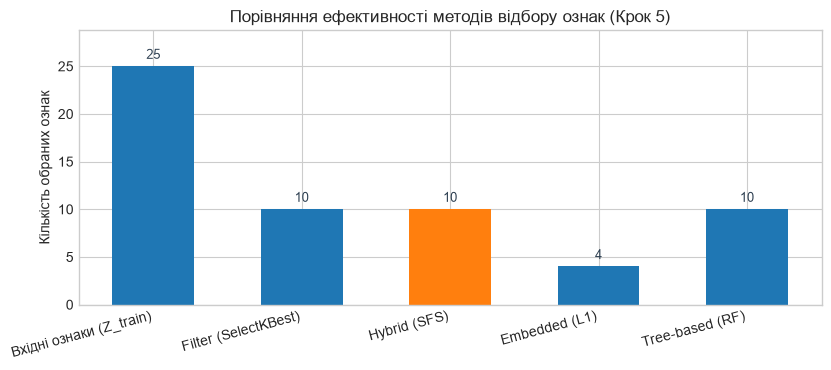

Консенсусні ознаки (обрані >= 2 методами):


,Feature,Filter,Hybrid_SFS,Embedded_L1,Tree_RF,votes
3,feat_04,True,True,True,True,4
6,feat_07,True,True,True,True,4
5,feat_06,True,True,True,True,4
13,feat_14,True,True,True,True,4
2,feat_03,True,True,False,True,3
10,feat_11,True,False,False,True,2
12,feat_13,True,True,False,False,2
19,feat_20,False,True,False,True,2
20,feat_21,False,True,False,True,2


In [4]:
## 4. Порівняльний аналіз та консенсус методів

# Порівняльний аналіз усіх методів відбору
summary_df, comp_table = compare_selections(
    Z_train.columns,
    filter_res['selected_features'],
    hybrid_res['selected_features'],
    embedded_res['selected_features'],
    tree_res['selected_features']
)
display(summary_df)

# Візуалізація кількості обраних ознак за кожним методом
counts = pd.Series({
    'Вхідні ознаки (Z_train)': Z_train.shape[1],
    'Filter (SelectKBest)': len(filter_res['selected_features']),
    'Hybrid (SFS)': len(hybrid_res['selected_features']),
    'Embedded (L1)': len(embedded_res['selected_features']),
    'Tree-based (RF)': len(tree_res['selected_features']),
})

fig, ax = plt.subplots(figsize=(8.5, 3.8))
bars = ax.bar(counts.index, counts.values, color=[ACCENT, ACCENT, SECOND, ACCENT, ACCENT], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + counts.max() * 0.02, f"{v}", ha="center", va="bottom", fontsize=9, color=INK)

ax.set_ylabel('Кількість обраних ознак')
ax.set_title('Порівняння ефективності методів відбору ознак (Крок 5)')
ax.set_ylim(0, counts.max() * 1.15)
plt.xticks(rotation=15, ha="right")
fig.tight_layout()
fig.savefig(REPORTS / 'lab2_feature_selection_comparison.png', bbox_inches='tight')
plt.show()

# Консенсус методів (Ознаки з найбільшою кількістю голосів)
consensus_df = comp_table[comp_table['votes'] >= 2].sort_values('votes', ascending=False)
consensus_df.to_csv(REPORTS / 'lab2_selected_features_consensus.csv', index=False)
print('Консенсусні ознаки (обрані >= 2 методами):')
display(consensus_df.head(15))